# Analisis tambahan untuk revisi naskah hs-CRP (sebelum jurnal ke-4)

Notebook ini menambah lima analisis yang diminta setelah penolakan HISS:

1. **Prediksi out-of-fold terkalibrasi**: validasi silang 5-fold *dikelompokkan per rumah tangga*, diulang, dengan kalibrasi ulang Platt di dalam setiap fold (tidak ada kebocoran data uji).
2. **Kalibrasi**: Brier score, calibration-in-the-large, slope, plot kalibrasi.
3. **Decision curve analysis (DCA)**: net benefit model dibanding "periksa semua" dan "tidak periksa siapa pun".
4. **Confusion matrix** modul 5 butir pada ambang rujukan (p ≥ 0,155) dan per 1.000 orang.
5. **Performa per subkelompok** (jenis kelamin, umur, kota/desa, kuintil pengeluaran), **uji buang-satu-variabel** pada modul 5 butir, dan **definisi outcome alternatif** (hs-CRP ≥ 2 mg/L).

Pembagian data, prediktor dan hyperparameter **identik** dengan notebook sebelumnya (seed 42).
Semua hasil disimpan di `results/analisis_revisi_jurnal4.xlsx` dan gambar `results/figS_dca.*`, `results/figS_subgroup.*`.
Perkiraan waktu: 10–30 menit (tergantung jumlah ulangan `REP_OOF`).

## 0. Persiapan (sama dengan notebook sebelumnya)

In [1]:
# === SEL 0: folder kerja dan file data ===
import os
ROOT = r"F:\SINTA 3\crp-ifls5-ml"
OUTDIR = os.path.join(ROOT, "results")
os.makedirs(OUTDIR, exist_ok=True)
os.chdir(OUTDIR)
DATA_FILE = os.path.join(ROOT, "data", "crp_ifls5_model.csv")
ANALYTIC_FILE = r"F:\SINTA 3\olahan_ifls5\ifls5_analytic.csv"   # untuk analisis CRP > 10 dan perbandingan peserta dikeluarkan
assert os.path.exists(DATA_FILE), f"Data tidak ditemukan: {DATA_FILE}"
print("Folder kerja :", os.getcwd())
print("Data model   :", DATA_FILE)
print("Data analitik:", ANALYTIC_FILE, "(ada)" if os.path.exists(ANALYTIC_FILE) else "(TIDAK ADA - analisis 4a dan 4c dilewati)")

# Jumlah ulangan validasi silang. 5 = cukup untuk naskah (sekitar 30-60 menit dengan DNN). Naikkan ke 10 bila ada waktu.
REPEATS = 5
RUN_DNN = False   # DNN tidak diperlukan untuk perbandingan ini

Folder kerja : F:\SINTA 3\crp-ifls5-ml\results
Data model   : F:\SINTA 3\crp-ifls5-ml\data\crp_ifls5_model.csv
Data analitik: F:\SINTA 3\olahan_ifls5\ifls5_analytic.csv (TIDAK ADA - analisis 4a dan 4c dilewati)


In [2]:
import warnings, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from scipy import stats
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold, RepeatedStratifiedKFold,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.base import clone, BaseEstimator, ClassifierMixin

def ada(m):
    try: __import__(m); return True
    except ImportError: return False
HAS_XGB, HAS_LGBM, HAS_TORCH = ada('xgboost'), ada('lightgbm'), ada('torch')
MODE = 'FINAL' if (HAS_XGB and HAS_LGBM) else 'PRATINJAU'
print(f'XGBoost={HAS_XGB} | LightGBM={HAS_LGBM} | PyTorch={HAS_TORCH} | MODE: {MODE}')
SEED = 42

XGBoost=True | LightGBM=True | PyTorch=True | MODE: FINAL


In [3]:
df = pd.read_csv(DATA_FILE, dtype={'pidlink': str, 'hhid14': str})
NUM = ['age', 'lnpce', 'hhsize', 'cig_day', 'pa_vig_days', 'pa_mod_days', 'pa_walk_days', 'bmi', 'sbp', 'dbp', 'n_chronic', 'cesd10']
BIN = ['female', 'married', 'widowed', 'urban', 'dx_hypert', 'dx_diab', 'dx_heart', 'dx_stroke', 'dx_chol',
       'dx_asthma', 'dx_lung', 'dx_arthritis', 'dx_kidney', 'dx_liver', 'dx_digest', 'med_hypert', 'med_diab', 'srh_poor']
CAT = ['educ', 'smoke_status']
FEATS = NUM + BIN + CAT
X, y, groups = df[FEATS].copy(), df.crp_high.values, df.hhid14.values

# Pembagian latih/uji IDENTIK dengan notebook utama (seed 42, stratified)
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(X, y, df.index, test_size=0.2, stratify=y, random_state=SEED)
hh_tr, hh_te = set(df.loc[idx_tr, 'hhid14']), df.loc[idx_te, 'hhid14']
shared = hh_te.isin(hh_tr)
n_hh = df.hhid14.nunique(); size = df.groupby('hhid14').size()
print(f'n = {len(df)}, kasus = {y.sum()} ({y.mean()*100:.1f}%) | rumah tangga = {n_hh}; '
      f'{(size > 1).sum()} rumah tangga punya >1 peserta ({size[size > 1].sum()} peserta)')
print(f'Data uji: {shared.sum()} dari {len(idx_te)} peserta ({shared.mean()*100:.1f}%) punya anggota rumah tangga di data latih')

def prep(scale, feats=FEATS):
    num, bin_, cat = [c for c in NUM if c in feats], [c for c in BIN if c in feats], [c for c in CAT if c in feats]
    num_steps = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    return ColumnTransformer([('num', Pipeline(num_steps), num), ('bin', SimpleImputer(strategy='most_frequent'), bin_),
                              ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                                ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)],
                             verbose_feature_names_out=False)

n = 5980, kasus = 904 (15.1%) | rumah tangga = 3655; 1505 rumah tangga punya >1 peserta (3830 peserta)
Data uji: 686 dari 1196 peserta (57.4%) punya anggota rumah tangga di data latih


In [4]:
# === Model dengan hyperparameter terbaik dari notebook utama ===
class BalancedMLP(MLPClassifier):
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y))

if HAS_TORCH:
    import torch, torch.nn as nn
    class TorchDNN(ClassifierMixin, BaseEstimator):
        def __init__(self, hidden=(64, 32), dropout=0.3, lr=1e-3, weight_decay=1e-5, epochs=300, batch=128, patience=25, seed=SEED):
            self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
            self.epochs, self.batch, self.patience, self.seed = epochs, batch, patience, seed
        def _net(self, d):
            layers = []
            for h in self.hidden: layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(self.dropout)]; d = h
            return nn.Sequential(*layers, nn.Linear(d, 1))
        def fit(self, X, y):
            torch.manual_seed(self.seed); X = np.asarray(X, np.float32); y = np.asarray(y, np.float32)
            self.classes_ = np.array([0, 1])
            Xa, Xv, ya, yv = train_test_split(X, y, test_size=0.15, stratify=y, random_state=self.seed)
            self.net_ = self._net(X.shape[1]); opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float((ya == 0).sum() / (ya == 1).sum())))
            Xa_t, ya_t, Xv_t = torch.tensor(Xa), torch.tensor(ya), torch.tensor(Xv)
            best, wait, state = -1, 0, None
            for ep in range(self.epochs):
                self.net_.train(); perm = torch.randperm(len(Xa_t))
                for i in range(0, len(perm), self.batch):
                    b = perm[i:i + self.batch]
                    if len(b) < 2: continue
                    opt.zero_grad(); lossf(self.net_(Xa_t[b]).squeeze(1), ya_t[b]).backward(); opt.step()
                self.net_.eval()
                with torch.no_grad(): auc = roc_auc_score(yv, self.net_(Xv_t).squeeze(1).numpy())
                if auc > best: best, wait, state = auc, 0, {k: v.clone() for k, v in self.net_.state_dict().items()}
                else:
                    wait += 1
                    if wait >= self.patience: break
            self.net_.load_state_dict(state); return self
        def predict_proba(self, X):
            self.net_.eval()
            with torch.no_grad(): p = torch.sigmoid(self.net_(torch.tensor(np.asarray(X, np.float32))).squeeze(1)).numpy()
            return np.c_[1 - p, p]
        def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

POS_W = (y_tr == 0).sum() / (y_tr == 1).sum()      # sama dengan notebook utama (5,62)
if HAS_XGB: from xgboost import XGBClassifier

def make_models(feats=FEATS):
    M = {}
    M['Logistic regression'] = Pipeline([('p', prep(True, feats)), ('m', LogisticRegression(C=0.011288378916846888, class_weight='balanced', max_iter=3000))])
    M['Random forest'] = Pipeline([('p', prep(False, feats)), ('m', RandomForestClassifier(n_estimators=500, max_depth=8, min_samples_leaf=40,
                                   max_features='sqrt', class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))])
    if HAS_XGB:
        M['XGBoost'] = Pipeline([('p', prep(False, feats)), ('m', XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.01, subsample=0.85, colsample_bytree=0.8,
                                 min_child_weight=10, scale_pos_weight=POS_W, eval_metric='logloss', n_jobs=-1, random_state=SEED))])
    else:
        M['HistGB (pengganti XGBoost)'] = Pipeline([('p', prep(False, feats)), ('m', HistGradientBoostingClassifier(class_weight='balanced', max_iter=200,
                                                   learning_rate=0.03, max_leaf_nodes=7, random_state=SEED))])
    if HAS_LGBM:
        from lightgbm import LGBMClassifier
        M['LightGBM'] = Pipeline([('p', prep(False, feats)), ('m', LGBMClassifier(n_estimators=200, num_leaves=15, learning_rate=0.01, min_child_samples=50,
                                  subsample=0.7, colsample_bytree=0.6, class_weight='balanced', random_state=SEED, verbose=-1))])
    M['MLP'] = Pipeline([('p', prep(True, feats)), ('m', BalancedMLP(hidden_layer_sizes=(64, 32), alpha=1.0, learning_rate_init=0.003, batch_size=64,
                         early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, max_iter=600, random_state=SEED))])
    if HAS_TORCH and RUN_DNN:
        M['DNN (PyTorch)'] = Pipeline([('p', prep(True, feats)), ('m', TorchDNN())])
    M['Ensemble (RF + MLP + LR)'] = VotingClassifier([('rf', clone(M['Random forest'])), ('mlp', clone(M['MLP'])),
                                                      ('lr', clone(M['Logistic regression']))], voting='soft')
    return M

MODELS = make_models()
print('Model:', list(MODELS))

Model: ['Logistic regression', 'Random forest', 'XGBoost', 'LightGBM', 'MLP', 'Ensemble (RF + MLP + LR)']


In [5]:
SIMPLE = {'LR: BMI only': ['bmi'],
          'LR: 5 items (BMI, sex, age, self-rated health, urban)': ['bmi', 'female', 'age', 'srh_poor', 'urban']}
def simple_model():
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                     ('m', LogisticRegression(class_weight='balanced', max_iter=2000))])

# Model pembanding dari notebook utama (dengan hyperparameter yang sama)
REF_MODELS = {k: v for k, v in MODELS.items() if k in ('Ensemble (RF + MLP + LR)', 'XGBoost', 'HistGB (pengganti XGBoost)', 'Logistic regression')}
print('Pembanding:', list(REF_MODELS), '| Model sederhana:', list(SIMPLE))

def sens_at_spec(yt, p, spec):
    f, t, _ = roc_curve(yt, p); return t[f <= 1 - spec].max()

Pembanding: ['Logistic regression', 'XGBoost', 'Ensemble (RF + MLP + LR)'] | Model sederhana: ['LR: BMI only', 'LR: 5 items (BMI, sex, age, self-rated health, urban)']


## 1. Pengaturan

In [6]:
# === SEL A: pengaturan analisis revisi ===
REP_OOF = 3          # ulangan CV per rumah tangga untuk prediksi out-of-fold (3 cukup; 5 lebih stabil)
N_BOOT = 500         # bootstrap per rumah tangga untuk interval kepercayaan
THR_REF = 0.155      # ambang rujukan modul 5 butir (probabilitas terkalibrasi, dari model card)
FIVE = ['bmi', 'female', 'age', 'srh_poor', 'urban']
LABEL = {'bmi': 'BMI', 'female': 'Female sex', 'age': 'Age', 'srh_poor': 'Poor self-rated health', 'urban': 'Urban residence'}
rng = np.random.default_rng(SEED)

# model yang dievaluasi: modul 5 butir, LR lengkap, model pohon terbaik, ensemble
GB_NAME = 'XGBoost' if 'XGBoost' in MODELS else 'HistGB (pengganti XGBoost)'
EVAL = {'Five-item LR (screening module)': ('simple', FIVE),
        'Full logistic regression': ('full', 'Logistic regression'),
        GB_NAME: ('full', GB_NAME),
        'Ensemble (RF + MLP + LR)': ('full', 'Ensemble (RF + MLP + LR)')}

def build(spec):
    kind, v = spec
    return Pipeline([('sel', ColumnTransformer([('k', 'passthrough', v)])), ('m', simple_model())]) if kind == 'simple' \
        else clone(MODELS[v])

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def fit_platt(p, yt):
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), yt)
    return lambda q: lr.predict_proba(logit(q).reshape(-1, 1))[:, 1]

print('Model dievaluasi:', list(EVAL))

Model dievaluasi: ['Five-item LR (screening module)', 'Full logistic regression', 'XGBoost', 'Ensemble (RF + MLP + LR)']


## 2. Prediksi out-of-fold terkalibrasi

In [7]:
# === SEL B: prediksi out-of-fold terkalibrasi (CV dikelompokkan per rumah tangga, Platt di dalam fold) ===
t0 = time.time()
Xall = df[FEATS].copy(); yall = df.crp_high.values; gall = df.hhid14.values

def oof_calibrated(spec, yv=yall, reps=REP_OOF):
    P = np.zeros((reps, len(yv)))
    for r in range(reps):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(Xall, yv, gall):
            m = build(spec).fit(Xall.iloc[tr], yv[tr])
            # Platt dihitung dari prediksi out-of-fold DATA LATIH saja (CV dalam, 3 fold per rumah tangga)
            inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
            p_in = np.zeros(len(tr))
            for a, b in inner.split(Xall.iloc[tr], yv[tr], gall[tr]):
                p_in[b] = build(spec).fit(Xall.iloc[tr].iloc[a], yv[tr][a]).predict_proba(Xall.iloc[tr].iloc[b])[:, 1]
            cal = fit_platt(p_in, yv[tr])
            P[r, te] = cal(m.predict_proba(Xall.iloc[te])[:, 1])
    return P.mean(0)

OOF = {}
for name, spec in EVAL.items():
    OOF[name] = oof_calibrated(spec); print(f'{name:35s} selesai ({(time.time()-t0)/60:.1f} menit)')
oof_df = pd.DataFrame(OOF); oof_df['y'] = yall; oof_df['hh'] = gall

Five-item LR (screening module)     selesai (0.5 menit)
Full logistic regression            selesai (1.0 menit)
XGBoost                             selesai (1.7 menit)
Ensemble (RF + MLP + LR)            selesai (7.3 menit)


## 3. Kalibrasi

Metric,AUC,AUC-PR,Brier,Brier (null),Calibration intercept (CITL),Calibration slope,O/E
Model,,,,,,,
Five-item LR (screening module),0.677,0.292,0.120,0.128,0.001,1.007,1.001
Full logistic regression,0.674,0.285,0.121,0.128,-0.002,1.005,0.998
XGBoost,0.684,0.308,0.119,0.128,-0.019,1.040,0.985
Ensemble (RF + MLP + LR),0.680,0.297,0.120,0.128,-0.005,1.031,0.996


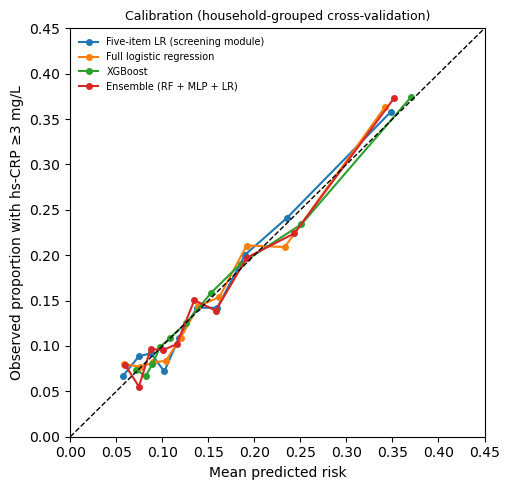

In [8]:
# === SEL C: diskriminasi dan kalibrasi (dengan CI bootstrap per rumah tangga) ===
from sklearn.metrics import confusion_matrix

def cal_slope_int(yt, p):
    lp = logit(p).reshape(-1, 1)
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(lp, yt).coef_[0][0]
    # calibration-in-the-large: intercept a dengan slope tetap 1, yaitu mean(y) = mean(sigmoid(logit(p) + a))
    from scipy.optimize import brentq
    citl = brentq(lambda a: (1 / (1 + np.exp(-(lp.ravel() + a)))).mean() - yt.mean(), -10, 10)
    return citl, slope

HH = pd.Series(gall); uniq = HH.unique(); idx_by_hh = HH.groupby(HH).indices
def boot_idx():
    pick = rng.choice(uniq, len(uniq), replace=True)
    return np.concatenate([idx_by_hh[h] for h in pick])

def metrics(yt, p):
    citl, slope = cal_slope_int(yt, p)
    return {'AUC': roc_auc_score(yt, p), 'AUC-PR': average_precision_score(yt, p), 'Brier': brier_score_loss(yt, p),
            'Brier (null)': brier_score_loss(yt, np.full(len(yt), yt.mean())),
            'Calibration intercept (CITL)': citl, 'Calibration slope': slope, 'O/E': yt.mean() / p.mean()}

BOOTS = [boot_idx() for _ in range(N_BOOT)]
rows = []
for name in EVAL:
    p = oof_df[name].values; est = metrics(yall, p)
    bs = pd.DataFrame([metrics(yall[b], p[b]) for b in BOOTS[:200]])   # 200 cukup untuk CI kalibrasi
    for k, v in est.items():
        lo, hi = bs[k].quantile([.025, .975])
        rows.append({'Model': name, 'Metric': k, 'Estimate': round(v, 3), '95% CI': f'{lo:.3f}–{hi:.3f}'})
CAL = pd.DataFrame(rows)
display(CAL.pivot(index='Model', columns='Metric', values='Estimate').loc[list(EVAL)])

# Plot kalibrasi (desil prediksi)
fig, ax = plt.subplots(figsize=(5.2, 5))
for name in EVAL:
    fy, fx = calibration_curve(yall, oof_df[name], n_bins=10, strategy='quantile')
    ax.plot(fx, fy, 'o-', ms=4, label=name)
ax.plot([0, .45], [0, .45], 'k--', lw=1); ax.set_xlim(0, .45); ax.set_ylim(0, .45)
ax.set_xlabel('Mean predicted risk'); ax.set_ylabel('Observed proportion with hs-CRP ≥3 mg/L')
ax.legend(fontsize=7, frameon=False); ax.set_title('Calibration (household-grouped cross-validation)', fontsize=9)
plt.tight_layout(); plt.savefig('figS_calibration_oof.png', dpi=300); plt.savefig('figS_calibration_oof.tiff', dpi=300); plt.show()

## 4. Decision curve analysis

,Model,Threshold,Net benefit,NB test-all,NB gain vs best default,95% CI (gain),Tests avoided per 100 vs test-all
0,Five-item LR (screening module),0.10,0.0637,0.0569,0.0069,0.0027 to 0.0110,6.2
1,Five-item LR (screening module),0.15,0.0401,0.0014,0.0387,0.0306 to 0.0432,21.9
2,Five-item LR (screening module),0.20,0.0260,-0.0610,0.0260,0.0194 to 0.0334,34.8
3,Five-item LR (screening module),0.25,0.0134,-0.1318,0.0134,0.0077 to 0.0193,43.5
4,Full logistic regression,0.10,0.0645,0.0569,0.0076,0.0033 to 0.0120,6.8
5,Full logistic regression,0.15,0.0397,0.0014,0.0384,0.0303 to 0.0429,21.7
6,Full logistic regression,0.20,0.0236,-0.0610,0.0236,0.0168 to 0.0310,33.9
7,Full logistic regression,0.25,0.0139,-0.1318,0.0139,0.0088 to 0.0199,43.7
8,XGBoost,0.10,0.0663,0.0569,0.0094,0.0047 to 0.0137,8.5
9,XGBoost,0.15,0.0424,0.0014,0.0411,0.0328 to 0.0460,23.3


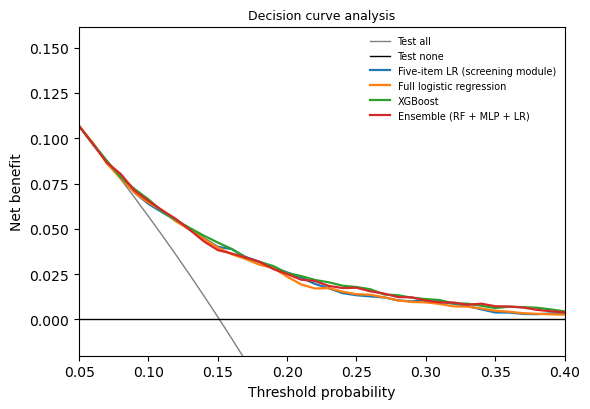

In [9]:
# === SEL D: decision curve analysis (net benefit) ===
TH = np.round(np.arange(0.05, 0.401, 0.01), 2)
def net_benefit(yt, p, t):
    n = len(yt); tp = ((p >= t) & (yt == 1)).sum(); fp = ((p >= t) & (yt == 0)).sum()
    return tp / n - fp / n * t / (1 - t)
prev = yall.mean()
dca = pd.DataFrame({'Threshold': TH, 'Test all': [prev - (1 - prev) * t / (1 - t) for t in TH], 'Test none': 0.0})
for name in EVAL:
    dca[name] = [net_benefit(yall, oof_df[name].values, t) for t in TH]

# Net benefit dengan CI bootstrap pada ambang kunci + "pemeriksaan yang dihindari per 100 orang" dibanding periksa semua
KEY = [0.10, 0.15, 0.20, 0.25]
rows = []
for name in EVAL:
    p = oof_df[name].values
    for t in KEY:
        nb = net_benefit(yall, p, t); nb_all = prev - (1 - prev) * t / (1 - t)
        bs = np.array([net_benefit(yall[b], p[b], t) - max(yall[b].mean() - (1 - yall[b].mean()) * t / (1 - t), 0) for b in BOOTS])
        avoided = (nb - nb_all) / (t / (1 - t)) * 100
        rows.append({'Model': name, 'Threshold': t, 'Net benefit': round(nb, 4), 'NB test-all': round(nb_all, 4),
                     'NB gain vs best default': round(nb - max(nb_all, 0), 4),
                     '95% CI (gain)': f'{np.percentile(bs, 2.5):.4f} to {np.percentile(bs, 97.5):.4f}',
                     'Tests avoided per 100 vs test-all': round(avoided, 1)})
DCA_KEY = pd.DataFrame(rows); display(DCA_KEY)

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(dca.Threshold, dca['Test all'], color='grey', lw=1, label='Test all')
ax.axhline(0, color='black', lw=1, label='Test none')
for name in EVAL: ax.plot(dca.Threshold, dca[name], lw=1.6, label=name)
ax.set_ylim(-0.02, prev + 0.01); ax.set_xlim(0.05, 0.40)
ax.set_xlabel('Threshold probability'); ax.set_ylabel('Net benefit')
ax.legend(fontsize=7, frameon=False); ax.set_title('Decision curve analysis', fontsize=9)
plt.tight_layout(); plt.savefig('figS_dca.png', dpi=300); plt.savefig('figS_dca.tiff', dpi=300); plt.show()

## 5. Confusion matrix modul 5 butir

In [10]:
# === SEL E: confusion matrix modul 5 butir pada ambang rujukan ===
p5 = oof_df['Five-item LR (screening module)'].values
def cm_row(yt, p, t, label):
    tn, fp, fn, tp = confusion_matrix(yt, (p >= t).astype(int), labels=[0, 1]).ravel()
    n = len(yt)
    return {'Setting': label, 'Threshold': t, 'n': n, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Flagged (%)': round((tp + fp) / n * 100, 1), 'Sensitivity': round(tp / (tp + fn), 3), 'Specificity': round(tn / (tn + fp), 3),
            'PPV': round(tp / (tp + fp), 3), 'NPV': round(tn / (tn + fn), 3),
            'Per 1000: flagged': round((tp + fp) / n * 1000), 'Per 1000: true cases flagged': round(tp / n * 1000),
            'Per 1000: cases missed': round(fn / n * 1000)}
rows = [cm_row(yall, p5, THR_REF, 'Out-of-fold (household-grouped CV), referral threshold')]
for t in (0.10, 0.20):
    rows.append(cm_row(yall, p5, t, f'Out-of-fold, alternative threshold {t:.2f}'))
CM = pd.DataFrame(rows); display(CM.T)

,0,1,2
Setting,"Out-of-fold (household-grouped CV), referral t...","Out-of-fold, alternative threshold 0.10","Out-of-fold, alternative threshold 0.20"
Threshold,0.155,0.1,0.2
n,5980,5980,5980
TP,538,740,390
FP,1660,3230,939
FN,366,164,514
TN,3416,1846,4137
Flagged (%),36.8,66.4,22.2
Sensitivity,0.595,0.819,0.431
Specificity,0.673,0.364,0.815


## 6. Performa per subkelompok

,Attribute,Group,n,Cases,AUC,AUC 95% CI,Sensitivity,Specificity,NPV,O/E
0,Sex,Female,3233,590,0.682,0.659–0.706,0.725,0.530,0.896,1.010
1,Sex,Male,2747,314,0.632,0.598–0.666,0.350,0.828,0.908,0.985
2,Age group,15–39,3064,426,0.706,0.675–0.735,0.542,0.769,0.912,1.054
3,Age group,40–59,1691,282,0.673,0.641–0.709,0.706,0.548,0.903,0.946
4,Age group,≥60,1225,196,0.598,0.554–0.640,0.551,0.599,0.875,0.976
5,Residence,Rural,2524,314,0.656,0.621–0.686,0.436,0.784,0.907,0.994
6,Residence,Urban,3456,590,0.681,0.656–0.703,0.680,0.588,0.899,1.005
7,Expenditure quintile,Q1–Q2 (poorest),2721,408,0.660,0.630–0.690,0.525,0.718,0.895,1.056
8,Expenditure quintile,Q3,1173,167,0.663,0.618–0.709,0.599,0.654,0.908,0.934
9,Expenditure quintile,Q4–Q5 (richest),2086,329,0.710,0.679–0.740,0.681,0.624,0.913,0.974


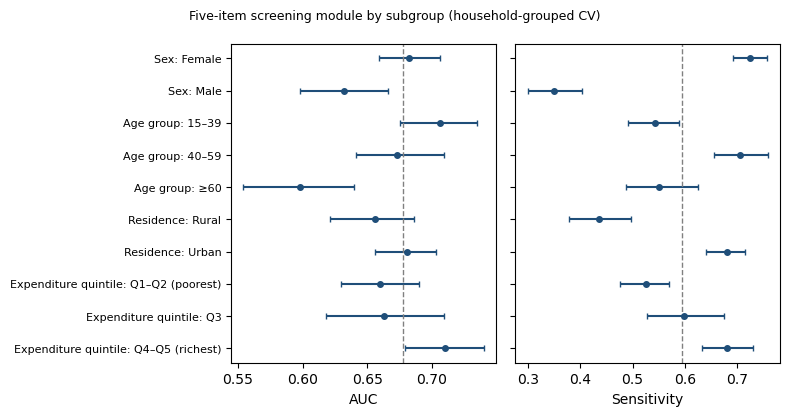

In [11]:
# === SEL F: performa per subkelompok (modul 5 butir dan ensemble) ===
age_g = pd.cut(df.age, [0, 39, 59, 200], labels=['15–39', '40–59', '≥60'])
pce_g = df.pce_quintile.map(lambda q: np.nan if pd.isna(q) else ('Q1–Q2 (poorest)' if q <= 2 else ('Q3' if q == 3 else 'Q4–Q5 (richest)')))
SUB = {'Sex': df.female.map({0: 'Male', 1: 'Female'}), 'Age group': age_g.astype(str),
       'Residence': df.urban.map({0: 'Rural', 1: 'Urban'}), 'Expenditure quintile': pce_g}

def sub_metrics(yt, p, t=THR_REF):
    pred = p >= t; tp = (pred & (yt == 1)).sum(); fn = (~pred & (yt == 1)).sum(); fp = (pred & (yt == 0)).sum(); tn = (~pred & (yt == 0)).sum()
    return {'AUC': roc_auc_score(yt, p) if 0 < yt.sum() < len(yt) else np.nan,
            'Sensitivity': tp / max(tp + fn, 1), 'Specificity': tn / max(tn + fp, 1),
            'PPV': tp / max(tp + fp, 1), 'NPV': tn / max(tn + fn, 1), 'O/E': yt.mean() / p.mean()}

rows = []
for mname in ['Five-item LR (screening module)', 'Ensemble (RF + MLP + LR)']:
    p = oof_df[mname].values
    for attr, g in SUB.items():
        for lvl in sorted(g.dropna().unique()):
            m = (g == lvl).fillna(False).values; yt, pp = yall[m], p[m]
            est = sub_metrics(yt, pp)
            # bootstrap per rumah tangga di dalam subkelompok
            hh_s = pd.Series(gall[m]); u = hh_s.unique(); ix = hh_s.groupby(hh_s).indices
            bs = []
            for _ in range(N_BOOT):
                b = np.concatenate([ix[h] for h in rng.choice(u, len(u), replace=True)])
                bs.append(sub_metrics(yt[b], pp[b]))
            bs = pd.DataFrame(bs)
            row = {'Model': mname, 'Attribute': attr, 'Group': lvl, 'n': int(m.sum()), 'Cases': int(yt.sum()),
                   'Prevalence (%)': round(yt.mean() * 100, 1)}
            for k, v in est.items():
                row[k] = round(v, 3); row[k + ' 95% CI'] = f'{bs[k].quantile(.025):.3f}–{bs[k].quantile(.975):.3f}'
            rows.append(row)
SUBG = pd.DataFrame(rows)
display(SUBG[SUBG.Model.str.startswith('Five')][['Attribute', 'Group', 'n', 'Cases', 'AUC', 'AUC 95% CI', 'Sensitivity', 'Specificity', 'NPV', 'O/E']])

# Gambar: AUC dan sensitivitas per subkelompok (modul 5 butir)
s5 = SUBG[SUBG.Model.str.startswith('Five')].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), sharey=True)
ylab = [f'{a}: {g}' for a, g in zip(s5.Attribute, s5.Group)]
for ax, k in zip(axes, ['AUC', 'Sensitivity']):
    lo = s5[k + ' 95% CI'].str.split('–').str[0].astype(float); hi = s5[k + ' 95% CI'].str.split('–').str[1].astype(float)
    ax.errorbar(s5[k], range(len(s5)), xerr=[s5[k] - lo, hi - s5[k]], fmt='o', ms=4, color='#1f4e79', capsize=2)
    overall = roc_auc_score(yall, p5) if k == 'AUC' else ((p5 >= THR_REF) & (yall == 1)).sum() / yall.sum()
    ax.axvline(overall, color='grey', ls='--', lw=1); ax.set_xlabel(k)
axes[0].set_yticks(range(len(s5))); axes[0].set_yticklabels(ylab, fontsize=8); axes[0].invert_yaxis()
fig.suptitle('Five-item screening module by subgroup (household-grouped CV)', fontsize=9)
plt.tight_layout(); plt.savefig('figS_subgroup.png', dpi=300); plt.savefig('figS_subgroup.tiff', dpi=300); plt.show()

## 7. Uji buang-satu-variabel

In [12]:
# === SEL G: uji buang-satu-variabel pada modul 5 butir (CV per rumah tangga, fold sama) ===
def cv_auc_cols(cols, yv=yall, reps=5):
    aucs = []
    for r in range(reps):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(Xall, yv, gall):
            m = simple_model().fit(Xall.iloc[tr][cols], yv[tr])
            aucs.append(roc_auc_score(yv[te], m.predict_proba(Xall.iloc[te][cols])[:, 1]))
    return np.array(aucs)

base = cv_auc_cols(FIVE)
rows = [{'Model': 'All five items', 'Mean CV AUC': round(base.mean(), 3), 'SD': round(base.std(), 3), 'ΔAUC vs five items': 0.0,
         '95% range of fold-wise Δ': '—'}]
for c in FIVE:
    a = cv_auc_cols([v for v in FIVE if v != c]); d = a - base   # selisih berpasangan pada fold yang sama
    rows.append({'Model': f'Without {LABEL[c]}', 'Mean CV AUC': round(a.mean(), 3), 'SD': round(a.std(), 3),
                 'ΔAUC vs five items': round(d.mean(), 3), '95% range of fold-wise Δ': f'{np.percentile(d, 2.5):.3f} to {np.percentile(d, 97.5):.3f}'})
full_lr = []
for r in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
    for tr, te in cv.split(Xall, yall, gall):
        m = clone(MODELS['Logistic regression']).fit(Xall.iloc[tr], yall[tr])
        full_lr.append(roc_auc_score(yall[te], m.predict_proba(Xall.iloc[te])[:, 1]))
full_lr = np.array(full_lr)
rows.append({'Model': 'Full logistic regression (all predictors)', 'Mean CV AUC': round(full_lr.mean(), 3), 'SD': round(full_lr.std(), 3),
             'ΔAUC vs five items': round((full_lr - base).mean(), 3),
             '95% range of fold-wise Δ': f'{np.percentile(full_lr - base, 2.5):.3f} to {np.percentile(full_lr - base, 97.5):.3f}'})
LOVO = pd.DataFrame(rows); display(LOVO)
print(f'Modul 5 butir mempertahankan {base.mean() / full_lr.mean() * 100:.1f}% AUC model LR lengkap '
      f'({(base.mean() - .5) / (full_lr.mean() - .5) * 100:.1f}% dari diskriminasi di atas peluang).')

,Model,Mean CV AUC,SD,ΔAUC vs five items,95% range of fold-wise Δ
0,All five items,0.678,0.025,0.000,—
1,Without BMI,0.612,0.028,-0.067,-0.096 to -0.037
2,Without Female sex,0.676,0.025,-0.002,-0.008 to 0.008
3,Without Age,0.677,0.024,-0.001,-0.005 to 0.008
4,Without Poor self-rated health,0.668,0.027,-0.010,-0.020 to 0.007
5,Without Urban residence,0.676,0.024,-0.002,-0.008 to 0.008
6,Full logistic regression (all predictors),0.675,0.025,-0.003,-0.016 to 0.006


Modul 5 butir mempertahankan 100.5% AUC model LR lengkap (101.9% dari diskriminasi di atas peluang).


## 8. Definisi outcome alternatif dan evaluasi berbobot survei

In [13]:
# === SEL H: definisi outcome alternatif (hs-CRP ≥ 2 mg/L) dan evaluasi berbobot survei ===
rows = []
for lab, yv in [('hs-CRP ≥3 mg/L (primary)', yall), ('hs-CRP ≥2 mg/L', (df.crp_plas_equi >= 2).astype(int).values)]:
    for name in ['Five-item LR (screening module)', 'Ensemble (RF + MLP + LR)']:
        spec = EVAL[name]; aucs = []
        for r in range(3):
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
            for tr, te in cv.split(Xall, yv, gall):
                aucs.append(roc_auc_score(yv[te], build(spec).fit(Xall.iloc[tr], yv[tr]).predict_proba(Xall.iloc[te])[:, 1]))
        rows.append({'Outcome': lab, 'Prevalence (%)': round(yv.mean() * 100, 1), 'Model': name,
                     'Mean CV AUC': round(np.mean(aucs), 3), 'SD': round(np.std(aucs), 3)})
OUTC = pd.DataFrame(rows); display(OUTC)

# Evaluasi berbobot survei (bobot DBS IFLS-5) atas prediksi out-of-fold
w = df.pwt14dbsxa.values; ok = ~np.isnan(w)
rows = []
for name in EVAL:
    p = oof_df[name].values
    rows.append({'Model': name, 'Weighted AUC': round(roc_auc_score(yall[ok], p[ok], sample_weight=w[ok]), 3),
                 'Weighted Brier': round(brier_score_loss(yall[ok], p[ok], sample_weight=w[ok]), 3),
                 'Weighted O/E': round(np.average(yall[ok], weights=w[ok]) / np.average(p[ok], weights=w[ok]), 3)})
WTD = pd.DataFrame(rows); display(WTD)

,Outcome,Prevalence (%),Model,Mean CV AUC,SD
0,hs-CRP ≥3 mg/L (primary),15.1,Five-item LR (screening module),0.678,0.027
1,hs-CRP ≥3 mg/L (primary),15.1,Ensemble (RF + MLP + LR),0.679,0.026
2,hs-CRP ≥2 mg/L,23.6,Five-item LR (screening module),0.681,0.015
3,hs-CRP ≥2 mg/L,23.6,Ensemble (RF + MLP + LR),0.682,0.016


,Model,Weighted AUC,Weighted Brier,Weighted O/E
0,Five-item LR (screening module),0.687,0.114,0.994
1,Full logistic regression,0.686,0.114,0.985
2,XGBoost,0.692,0.113,0.965
3,Ensemble (RF + MLP + LR),0.691,0.113,0.981


## 9. Simpan hasil

In [14]:
# === SEL I: simpan semua hasil ===
with pd.ExcelWriter('analisis_revisi_jurnal4.xlsx') as xw:
    CAL.to_excel(xw, sheet_name='kalibrasi_oof', index=False)
    DCA_KEY.to_excel(xw, sheet_name='dca_ambang_kunci', index=False)
    dca.round(4).to_excel(xw, sheet_name='dca_kurva', index=False)
    CM.to_excel(xw, sheet_name='confusion_matrix', index=False)
    SUBG.to_excel(xw, sheet_name='subkelompok', index=False)
    LOVO.to_excel(xw, sheet_name='buang_satu_variabel', index=False)
    OUTC.to_excel(xw, sheet_name='definisi_outcome', index=False)
    WTD.to_excel(xw, sheet_name='berbobot_survei', index=False)
    pd.DataFrame({'info': [f'REP_OOF={REP_OOF}', f'N_BOOT={N_BOOT}', f'THR_REF={THR_REF}', f'MODE={MODE}',
                           f'waktu total {(time.time()-t0)/60:.1f} menit']}).to_excel(xw, sheet_name='info', index=False)
print('Tersimpan: results/analisis_revisi_jurnal4.xlsx, figS_calibration_oof, figS_dca, figS_subgroup (.png dan .tiff)')

Tersimpan: results/analisis_revisi_jurnal4.xlsx, figS_calibration_oof, figS_dca, figS_subgroup (.png dan .tiff)


In [15]:
# === SEL J: validasi geografis (latih di wilayah lain, uji di satu wilayah) ===
print('Contoh isi kolom province:', df.province.unique()[:15])
prov = pd.to_numeric(df.province, errors='coerce')
REGION = {1: 'Sumatra', 3: 'Java', 5: 'Bali–Nusa Tenggara', 6: 'Kalimantan', 7: 'Sulawesi'}
if prov.isna().mean() > 0.5:
    print('Kode provinsi bukan angka BPS -> kirim output ini ke Claude')
else:
    region = (prov // 10).map(REGION).fillna('Other'); print(region.value_counts())
    rows = []
    for reg in [r for r in REGION.values() if (region == r).sum() >= 200]:
        te = (region == reg).values; tr = ~te
        for name in ['Five-item LR (screening module)', 'Ensemble (RF + MLP + LR)']:
            spec = EVAL[name]; Xtr, ytr, gtr = Xall[tr], yall[tr], gall[tr]
            m = build(spec).fit(Xtr, ytr)
            inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED); p_in = np.zeros(tr.sum())
            for a, b in inner.split(Xtr, ytr, gtr):
                p_in[b] = build(spec).fit(Xtr.iloc[a], ytr[a]).predict_proba(Xtr.iloc[b])[:, 1]
            p = fit_platt(p_in, ytr)(m.predict_proba(Xall[te])[:, 1]); yt = yall[te]
            hh_s = pd.Series(gall[te]); u = hh_s.unique(); ix = hh_s.groupby(hh_s).indices; aucs = []
            for _ in range(200):
                bb = np.concatenate([ix[h] for h in rng.choice(u, len(u), replace=True)])
                if 0 < yt[bb].sum() < len(bb): aucs.append(roc_auc_score(yt[bb], p[bb]))
            citl, slope = cal_slope_int(yt, p); pred = p >= THR_REF
            rows.append({'Held-out region': reg, 'Model': name, 'n': int(te.sum()), 'Cases': int(yt.sum()),
                         'AUC': round(roc_auc_score(yt, p), 3), 'AUC 95% CI': f'{np.percentile(aucs,2.5):.3f}–{np.percentile(aucs,97.5):.3f}',
                         'Calibration intercept': round(citl, 3), 'Calibration slope': round(slope, 3), 'O/E': round(yt.mean()/p.mean(), 3),
                         'Sensitivity': round((pred & (yt==1)).sum()/yt.sum(), 3), 'Specificity': round((~pred & (yt==0)).sum()/(yt==0).sum(), 3)})
    GEO = pd.DataFrame(rows); display(GEO)
    GEO.to_excel('analisis_revisi_geografis.xlsx', index=False); print('Tersimpan: results/analisis_revisi_geografis.xlsx')

Contoh isi kolom province: [12. 31. 14. 33. 32. 13. 15. 35. 34. 21. 51. 16. 19. 36. 18.]
province
Java                  3421
Sumatra               1237
Bali–Nusa Tenggara     704
Sulawesi               336
Kalimantan             275
Other                    7
Name: count, dtype: int64


,Held-out region,Model,n,Cases,AUC,AUC 95% CI,Calibration intercept,Calibration slope,O/E,Sensitivity,Specificity
0,Sumatra,Five-item LR (screening module),1237,187,0.713,0.671–0.760,0.005,1.235,1.004,0.652,0.685
1,Sumatra,Ensemble (RF + MLP + LR),1237,187,0.710,0.673–0.751,-0.019,1.196,0.985,0.647,0.675
2,Java,Five-item LR (screening module),3421,522,0.675,0.651–0.703,0.000,1.022,1.000,0.571,0.664
3,Java,Ensemble (RF + MLP + LR),3421,522,0.681,0.659–0.706,0.040,1.064,1.033,0.569,0.682
4,Bali–Nusa Tenggara,Five-item LR (screening module),704,82,0.649,0.575–0.717,-0.260,0.909,0.805,0.573,0.685
5,Bali–Nusa Tenggara,Ensemble (RF + MLP + LR),704,82,0.649,0.576–0.728,-0.234,0.924,0.824,0.537,0.706
6,Kalimantan,Five-item LR (screening module),275,47,0.619,0.539–0.692,0.139,0.604,1.115,0.468,0.649
7,Kalimantan,Ensemble (RF + MLP + LR),275,47,0.634,0.544–0.708,0.170,0.770,1.145,0.426,0.680
8,Sulawesi,Five-item LR (screening module),336,66,0.669,0.593–0.749,0.391,1.019,1.358,0.576,0.704
9,Sulawesi,Ensemble (RF + MLP + LR),336,66,0.665,0.558–0.754,0.447,0.903,1.413,0.530,0.726


Tersimpan: results/analisis_revisi_geografis.xlsx
